# 06 · Teste de hipóteses por dados substitutos
## 1. Introdução científica e pergunta de pesquisa

As séries diárias regionais de temperatura e precipitação do **Xingu** e do
**Baixo Tapajós** têm dependências temporais incompatíveis com hipóteses específicas
de processos estocásticos lineares estacionários? A pergunta antecede qualquer
estimativa de dimensão ou expoente de Lyapunov. Uma rejeição **não comprova caos**;
não rejeitar **não comprova linearidade**. ERA5 é uma reanálise, não uma observação
direta em cada célula. Aqui não atribuímos diferenças ao desmatamento.

O notebook reaproveita `regional.summarize`, `regional_frame`, `anomalies`, o estilo
`viz.style` e os controles `nonlinear.synthetic`. Os notebooks 04, 05 e o laboratório
permanecem preservados. Aquisição e ETL continuam nas ferramentas existentes.
Se faltarem dados locais, os resultados sintéticos ficam **explicitamente separados**
e os testes ERA5 são registrados como não executados; não há download automático.

## 2. Fundamentação teórica e formulação das hipóteses

Para $x_t$, com $N$ observações igualmente espaçadas, seja
$X_k=\sum_{t=0}^{N-1}x_t\exp(-2\pi i kt/N)$ a transformada discreta.
**FT:** substituímos as fases internas por variáveis uniformes independentes em
$[0,2\pi)$, conservando $|X_k|$. DC ($k=0$) e Nyquist (apenas $N$ par) mantêm seus
valores reais com sinal; `rfft/irfft` garante a simetria conjugada e saída real.
O periodograma e a ACF **circular** são preservados até precisão numérica. A ACF
usual, sem conexão entre as extremidades, pode diferir. A hipótese é um processo
linear **gaussiano estacionário**, condicionado ao espectro estimado; extremos
do registro, duração finita e fases não intercambiáveis limitam a calibração.

**IAAFT:** alternamos a projeção no espectro observado e a ordenação que atribui
os valores originais às posições dos novos postos. A distribuição empírica é
preservada **exatamente**; o espectro apenas aproximadamente. A hipótese permite
uma transformação **estática monotônica** de um processo linear gaussiano
estacionário. Empates, chuva intermitente e ciclos de variância desafiam essa
hipótese. Não confundimos o encerramento da iteração com erro espectral nulo.

Medimos $e=\|\,|X_k^*|-|X_k|\,\|_2/\|\,|X_k|\,\|_2$ para $k>0$.
O erro exclui DC e compara **amplitudes Fourier**, não potências. O protocolo
sinaliza $e>0{,}02$; esse limiar é diagnóstico, não garantia de validade.
Nunca escolhemos apenas substitutas com valores-p favoráveis.

Referências primárias (formulações e ressalvas):
- [Theiler et al. (1992), Testing for nonlinearity in time series](https://doi.org/10.1016/0167-2789(92)90102-S).
- [Schreiber (1999), Interdisciplinary application of nonlinear time series methods](https://doi.org/10.1016/S0370-1573(98)00035-0).
- [Schreiber e Schmitz (2000), Surrogate time series](https://doi.org/10.1016/S0167-2789(00)00043-9).
- [Schreiber e Schmitz, Improved surrogate data](https://arxiv.org/abs/chao-dyn/9909041).
- [Schmitz e Schreiber, sinais não estacionários](https://arxiv.org/abs/chao-dyn/9904023).
- [Sivakumar (2000), limitações em hidrologia](https://doi.org/10.1016/S0022-1694(99)00186-9).
- [Sivakumar et al. (2001), Evidence of chaos in the rainfall–runoff process](https://doi.org/10.1080/02626660109492805).

## 3. Configuração e carregamento dos dados

As escolhas abaixo ficam registradas **antes dos resultados**. Família primária:
duas regiões × temperatura em anomalias × FT/IAAFT × assimetria no atraso 1,
totalizando quatro hipóteses, corrigidas por Holm. Chuva, série original,
previsão e demais atrasos/janelas são exploratórios (BH separado). Alterar a
configuração constitui outro protocolo, não uma busca pelo menor valor-p.

O padrão usa 199 substitutas e α=0,05. O modo rápido usa 19 e destina-se somente
à validação computacional; sua resolução mínima 0,05 é inadequada para conclusões
robustas e comparações múltiplas. Resultados rápidos recebem outra pasta.

In [1]:
from pathlib import Path
from functools import partial
import hashlib
import importlib.metadata as metadata
import json
import platform
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy.signal import periodogram
from scipy.stats import binomtest
from statsmodels.tsa.stattools import acf

from amazon_chaos.nonlinear.statistics import time_reversal_asymmetry, nonlinear_prediction_error
from amazon_chaos.nonlinear.surrogates import surrogate_test, iaaft_surrogate
from amazon_chaos.nonlinear.synthetic import ar1, logistic_map
from amazon_chaos.nonlinear.surrogate_study import (
    NULLS, local_inventory, load_local_region, prepare_climate_series,
    quality_report, stationarity_diagnostics, adjust_results,
)
from amazon_chaos.viz import style, save, COLORS

style()
ROOT = Path.cwd()
assert (ROOT / 'pyproject.toml').exists(), 'Execute o kernel na raiz do repositório.'

In [2]:
QUICK = False  # somente validação de código; padrão científico: False

In [3]:
CONFIG = {
    'regions': ['xingu', 'tapajos'], 'variables': ['t2m', 'precip'],
    'archive': [1990, 2024], 'period': ['2001-01-01', '2024-12-31'],
    'base': ['1991-01-01', '2020-12-31'], 'resolution': 'D',
    'versions': ['original', 'anomaly'], 'methods': ['FT', 'IAAFT'],
    'statistics': ['asymmetry', 'prediction'], 'primary_lag': 1,
    'n_surrogates': 19 if QUICK else 199, 'alpha': .05, 'seed': 20261013,
    'iaaft_max_iter': 1000, 'iaaft_tolerance': 1e-8, 'spectral_warning': .02,
    'climatology_window': 31, 'minimum_climate_samples': 365,
    'prediction': {'dimension': 3, 'delay': 1, 'horizon': 1, 'neighbors': 5,
                   'theiler': 14, 'train_fraction': .6},
    'stationarity_blocks': 4, 'hac_lags': 14,
    'calibration_repeats': 8 if QUICK else 40, 'calibration_length': 512,
    'sensitivity_lags': [1, 7, 30], 'sensitivity_lengths': [256, 1024],
    'sensitivity_noise': [0., .3],
    'sensitivity_windows': [['2001-01-01', '2012-12-31'], ['2013-01-01', '2024-12-31']],
}
configuration_json = json.dumps(CONFIG, sort_keys=True, ensure_ascii=False)
RUN_ID = ('quick_' if QUICK else 'full_') + hashlib.sha256(configuration_json.encode()).hexdigest()[:10]
OUT = ROOT / 'experiments/surrogates' / RUN_ID
FIGURES = ROOT / 'reports/figures/surrogates' / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
versions = {p: metadata.version(p) for p in ['amazon-chaos', 'numpy', 'scipy', 'pandas',
                                           'statsmodels', 'matplotlib', 'xarray', 'nbclient']}
revision = subprocess.run(['git', 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
manifest = {'config': CONFIG, 'versions': versions, 'python': platform.python_version(),
            'git_head': revision, 'quick_validation_only': QUICK}
(OUT / 'config.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.Series(CONFIG, name='protocolo pré-definido').to_frame())
inventory = local_inventory(ROOT, CONFIG['regions'], *CONFIG['archive'])
inventory.to_csv(OUT / 'inventory.csv', index=False)
display(inventory.groupby(['region', 'kind']).available.agg(['sum', 'count']))

real_data, availability = {}, []
for region in CONFIG['regions']:
    try:
        frame, units, provenance = load_local_region(ROOT, region, *CONFIG['archive'])
        real_data[region] = (frame, units, provenance)
        availability.append({'region': region, 'status': 'disponível', 'detail': provenance})
    except FileNotFoundError as exc:
        availability.append({'region': region, 'status': 'não executado: dados ausentes', 'detail': str(exc)})
availability = pd.DataFrame(availability)
availability.to_csv(OUT / 'availability.csv', index=False)
display(availability)

,protocolo pré-definido
regions,"[xingu, tapajos]"
variables,"[t2m, precip]"
archive,"[1990, 2024]"
period,"[2001-01-01, 2024-12-31]"
base,"[1991-01-01, 2020-12-31]"
resolution,D
versions,"[original, anomaly]"
methods,"[FT, IAAFT]"
statistics,"[asymmetry, prediction]"
primary_lag,1


sum  count
region  kind               
tapajos daily      0     35
        summary    0      1
xingu   daily      0     35
        spatial    0      2
        summary    0      1

,region,status,detail
0,xingu,não executado: dados ausentes,ERA5 regional ausente; veja inventory.csv para...
1,tapajos,não executado: dados ausentes,ERA5 regional ausente; veja inventory.csv para...


Os arquivos esperados são `data/processed/<experimento>/daily_<ano>-01-01_<ano>-12-31.nc`
de 1990 a 2024, ou um resumo `summary_1990_2024.nc` transferido do ambiente de
processamento. O inventário lista **cada caminho ausente**, inclusive a máscara
`basin_grid.geojson` e a bacia do Xingu. Um resumo isolado é utilizável, mas sua
proveniência não pode ser revalidada sem os diários. O pipeline regional renormaliza
pesos sobre células válidas: lacunas espaciais podem mudar o suporte da média;
o resumo sozinho não certifica suporte fixo. A análise real permanece exploratória.

Para obter dados já existentes no HPC, siga `docs/HPC_EDH.md`, seção 3 (rsync).
Para processamento explícito dos brutos já presentes:
```bash
uv run python -m amazon_chaos.pilot_cli process 2001-01-01 2001-12-31 --config configs/xingu_1990_2024.yaml --source edh
```
Repita por ano e recorte. Para **nova aquisição**, planeje separadamente o volume,
credenciais e recursos conforme o mesmo documento; os comandos de download
`edh-download`/Slurm não são chamados neste caderno.

## 4. Inspeção e pré-processamento das séries

A temperatura é média de 24 observações horárias em °C. A precipitação é o
**total diário em mm**, depois da atribuição da hora acumulada ao dia correto;
dias locais completos usam UTC−3. As médias espaciais são ponderadas por área
dentro da bacia/caixa. Valores negativos de chuva e metadados de unidade
desconhecidos bloqueiam o protocolo, sem correção silenciosa.

A escala diária conserva milhares de amostras e processos sinóticos; conclusões
não se extrapolam automaticamente à escala horária ou mensal. `7D` é uma opção
explícita: média de temperatura, soma de chuva, só blocos completos de sete dias.
Não usamos meses como pontos equidistantes em Fourier.

Anomalia: $a_t=x_t-\bar x_{d(t)}$, em que $\bar x$ é a climatologia diária
1991–2020 suavizada por janela circular de 31 dias, calculada pela rotina
`regional.anomalies`. A rotina usa dia ordinal do ano: após fevereiro, anos
bissextos têm um deslocamento de um dia. Esse efeito e a suavização devem entrar
numa futura sensibilidade de calendário; não alteramos os notebooks regionais.
Exigimos a referência completa, sem interpolar o sinal nem inventar a normal.

**Remover a média sazonal não remove sazonalidade da variância**, tendência,
rupturas nem mudança de autocorrelação. Mostramos quatro blocos de média,
desvio e ACF(1), tendência OLS com erros HAC (14 atrasos), ADF com 14 atrasos
fixos, KPSS de nível e CUSUM descritivo. ADF tem nula de raiz unitária; KPSS,
de estacionariedade em nível. Valores-p de KPSS podem ser apenas limites tabulados.
CUSUM convencional sofre com dependência serial. Nenhum teste certifica
estacionariedade. Limiares de heterogeneidade são alertas pré-definidos, não
testes calibrados. Alertas fazem a interpretação **exploratória**, sem remoção
automática de tendências. A série original sazonal também é exploratória.

In [4]:
climate_series, qc_rows, stationarity_rows = {}, [], []
for region, (frame, units, provenance) in real_data.items():
    for variable in CONFIG['variables']:
        if variable not in frame:
            qc_rows.append({'region': region, 'variable': variable, 'error': 'variável ausente'})
            continue
        s = frame[variable]
        qc = quality_report(s.loc[CONFIG['period'][0]:CONFIG['period'][1]], variable, *CONFIG['period'])
        qc_rows.append({'region': region, 'variable': variable, 'units': units[variable], **qc})
        fig, axes = plt.subplots(2, 1, figsize=(12, 5), layout='constrained')
        axes[0].plot(s.index, s.values, lw=.4, color=COLORS[variable], label='original ERA5')
        axes[0].set(ylabel=units[variable], title=f'{region} · {variable} · arquivo 1990–2024 · dias locais UTC−3')
        axes[0].legend()
        for version in CONFIG['versions']:
            key = (region, variable, version)
            try:
                allowed = {'degC', '°C'} if variable == 't2m' else {'mm', 'mm/day', 'mm/dia'}
                if units[variable] not in allowed:
                    raise ValueError(f'Unidade não validada: {units[variable]!r}')
                if qc['extreme_temperature'] or qc['negative_rain']:
                    raise ValueError('Valores fisicamente suspeitos: revisar sem remover automaticamente')
                prepared = prepare_climate_series(s, variable=variable, period=CONFIG['period'],
                    base=CONFIG['base'], version=version, resolution=CONFIG['resolution'],
                    climatology_window=CONFIG['climatology_window'])
                if len(prepared) < CONFIG['minimum_climate_samples']:
                    raise ValueError('Amostra climática insuficiente para o protocolo')
                diag, blocks = stationarity_diagnostics(prepared, CONFIG['stationarity_blocks'], CONFIG['hac_lags'])
                stationarity_rows.append({'region': region, 'variable': variable, 'version': version, **diag})
                blocks.to_csv(OUT / f'blocks_{region}_{variable}_{version}.csv', index=False)
                climate_series[key] = (prepared, diag, provenance)
                if version == 'anomaly':
                    axes[1].plot(prepared.index, prepared, lw=.4, label='anomalias 1991–2020')
                roll = prepared.rolling(365, min_periods=365)
                roll_stats = pd.DataFrame({'mean': roll.mean(), 'std': roll.std()})
                roll_stats.to_csv(OUT / f'rolling_{region}_{variable}_{version}.csv')
                fig_diag, diag_axes = plt.subplots(3, 1, figsize=(11, 7), layout='constrained')
                diag_axes[0].plot(roll_stats.index, roll_stats['mean'], label='média móvel 365 amostras')
                diag_axes[1].plot(roll_stats.index, roll_stats['std'], label='desvio móvel 365 amostras')
                diag_axes[2].plot(blocks.block, blocks.acf1, 'o-', label='ACF(1) em quatro blocos')
                for ax in diag_axes:
                    ax.legend()
                diag_axes[0].set(ylabel=units[variable])
                diag_axes[1].set(ylabel=units[variable])
                diag_axes[2].set(xlabel='bloco cronológico', ylabel='ACF(1)')
                fig_diag.suptitle(f'ERA5 · {region} · {variable} · {version} · {CONFIG["period"]}')
                save(fig_diag, FIGURES, f'stationarity_{region}_{variable}_{version}')
                plt.show()
                plt.close()
                plt.close(fig_diag)
            except ValueError as exc:
                stationarity_rows.append({'region': region, 'variable': variable, 'version': version,
                                          'status': 'bloqueado', 'flags': str(exc)})
        axes[1].set(ylabel=units[variable], title=f'{region} · {variable} · anomalias · {CONFIG["period"]}')
        if axes[1].lines:
            axes[1].legend()
        save(fig, FIGURES, f'climate_{region}_{variable}')
        plt.show()
        plt.close()
qc_frame = pd.DataFrame(qc_rows) if qc_rows else pd.DataFrame(columns=['region', 'variable', 'units', 'n', 'error'])
stationarity_frame = pd.DataFrame(stationarity_rows) if stationarity_rows else pd.DataFrame(columns=['region', 'variable', 'version', 'status', 'flags'])
qc_frame.to_csv(OUT / 'quality.csv', index=False)
stationarity_frame.to_csv(OUT / 'stationarity.csv', index=False)
if not real_data:
    display(Markdown('**ERA5 ausente:** inspeção climática não executada. Figuras seguintes são sintéticas.'))
else:
    display(pd.DataFrame(qc_rows))
    display(pd.DataFrame(stationarity_rows))

**ERA5 ausente:** inspeção climática não executada. Figuras seguintes são sintéticas.

## 5. Geração e validação de surrogates

Cada substituta parte de uma permutação/fases independentes, com fluxos gerados
por `SeedSequence`. Não significa que IAAFT amostre uniformemente todas as séries
com essas restrições. Mantemos diagnósticos de **todas** as substitutas, incluindo
erro espectral, erro máximo dos valores ordenados, iterações e motivo de parada.
A comparação abaixo usa AR(1) sintético antes de olhar as estatísticas climáticas.

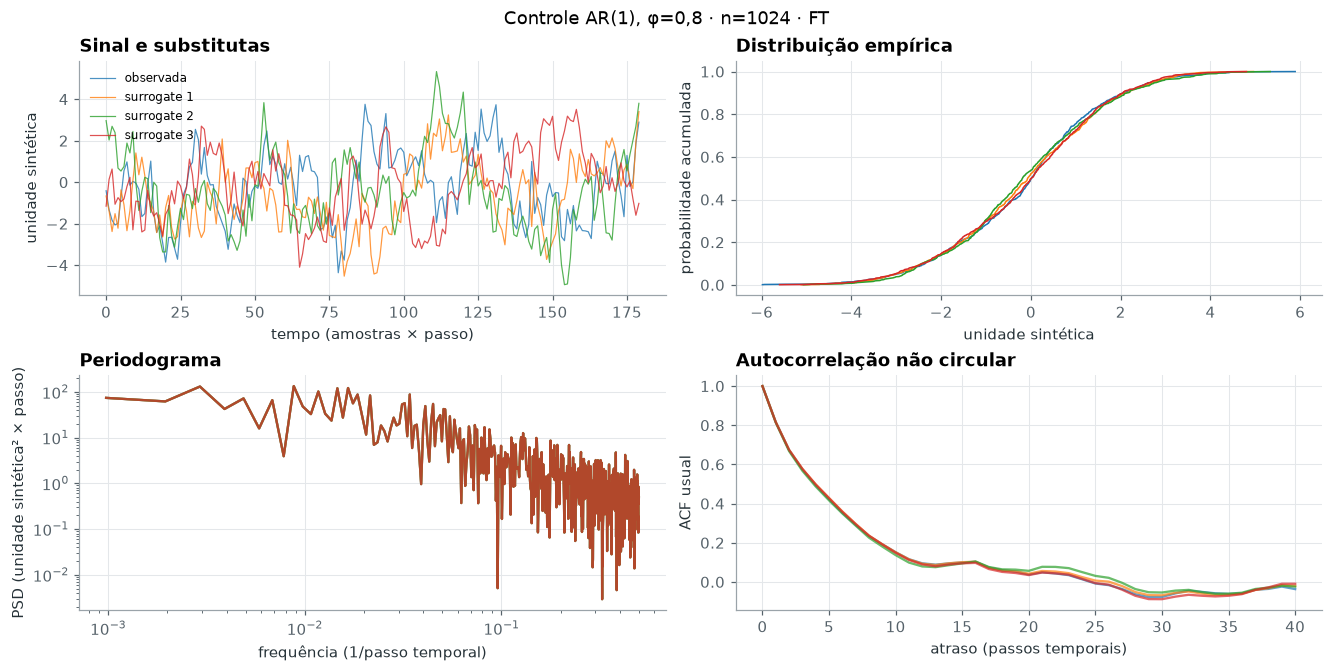

,iterations,converged,stop_reason,spectral_error,amplitude_max_error
count,199.0,199,199,1.990000e+02,199.000000
unique,NaN,1,1,NaN,NaN
top,NaN,True,exact_FT,NaN,NaN
freq,NaN,199,199,NaN,NaN
mean,1.0,NaN,NaN,2.610984e-16,1.115191
std,0.0,NaN,NaN,1.248433e-17,0.304025
min,1.0,NaN,NaN,2.223184e-16,0.438832
25%,1.0,NaN,NaN,2.532211e-16,0.872329
50%,1.0,NaN,NaN,2.612995e-16,1.086564
75%,1.0,NaN,NaN,2.698509e-16,1.348233


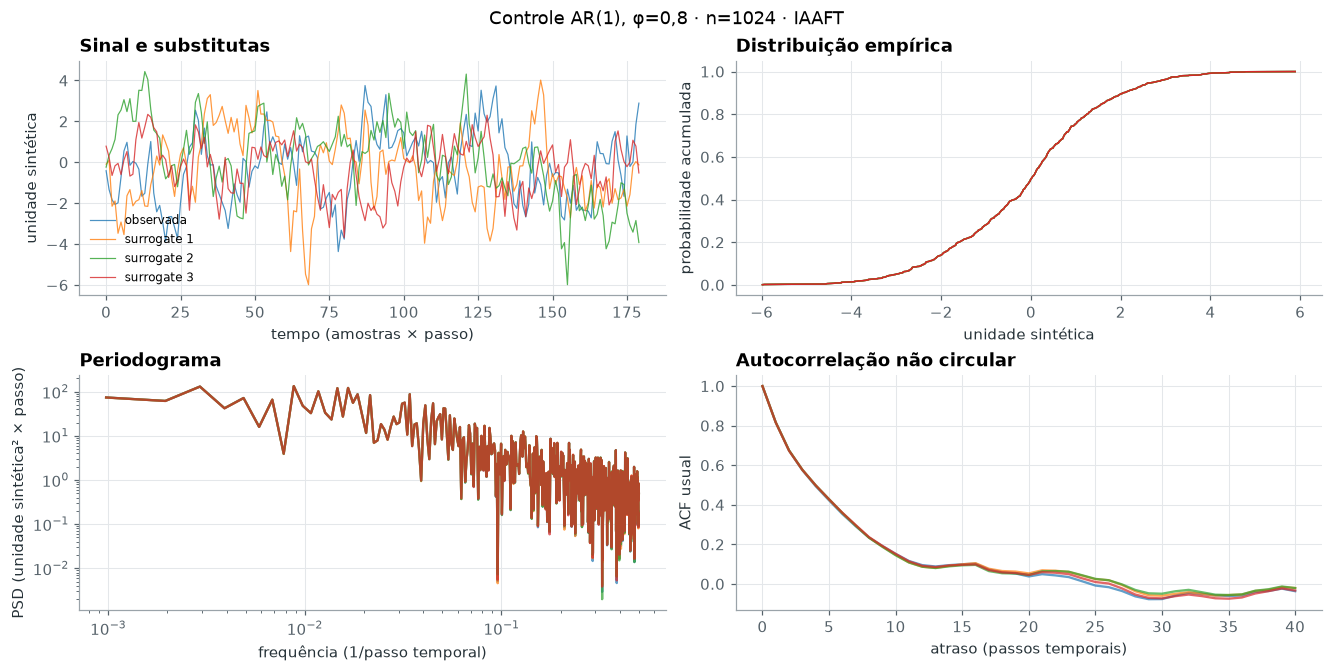

,iterations,converged,stop_reason,spectral_error,amplitude_max_error
count,199.000000,199,199,199.000000,199.0
unique,NaN,1,1,NaN,NaN
top,NaN,False,fixed_ranks,NaN,NaN
freq,NaN,199,199,NaN,NaN
mean,37.100503,NaN,NaN,0.003839,0.0
std,8.170528,NaN,NaN,0.000272,0.0
min,24.000000,NaN,NaN,0.003261,0.0
25%,32.000000,NaN,NaN,0.003647,0.0
50%,36.000000,NaN,NaN,0.003818,0.0
75%,40.000000,NaN,NaN,0.003990,0.0


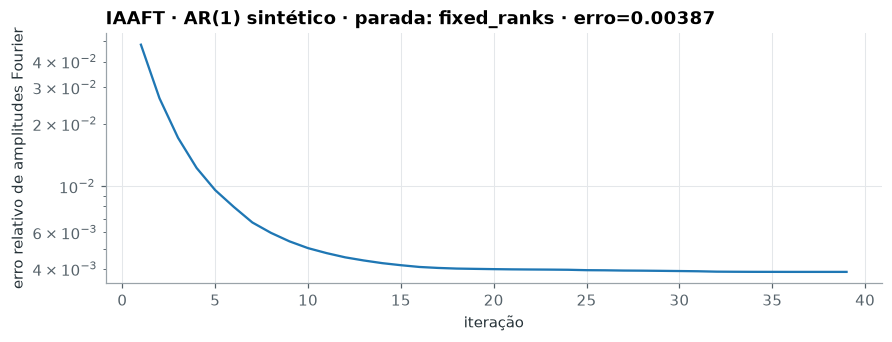

In [5]:
def run_test(x, method, statistic='asymmetry', lag=None, seed=None):
    if statistic == 'asymmetry':
        discriminant = partial(time_reversal_asymmetry, lag=CONFIG['primary_lag'] if lag is None else lag)
        alternative = 'absolute'
    elif statistic == 'prediction':
        discriminant = partial(nonlinear_prediction_error, **CONFIG['prediction'])
        alternative = 'less'
    else:
        raise ValueError('Estatística deve ser asymmetry ou prediction')
    return surrogate_test(x, discriminant, method=method, n_surrogates=CONFIG['n_surrogates'],
        seed=CONFIG['seed'] if seed is None else seed, alternative=alternative,
        max_iter=CONFIG['iaaft_max_iter'], tolerance=CONFIG['iaaft_tolerance'])

def plot_validation(x, result, title, unit='unidade sintética', step=1):
    fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout='constrained')
    curves = [('observada', np.asarray(x))] + [(f'surrogate {i+1}', y) for i, y in enumerate(result.examples)]
    for label, y in curves:
        axes[0, 0].plot(np.arange(min(180, len(y))) * step, y[:180], lw=.8, alpha=.8, label=label)
        ordered = np.sort(y)
        axes[0, 1].plot(ordered, np.arange(1, len(y)+1)/len(y), lw=1, label=label)
        f, power = periodogram(y, fs=1/step, window='boxcar', detrend='constant')
        axes[1, 0].loglog(f[1:], np.maximum(power[1:], 1e-20), alpha=.7)
        axes[1, 1].plot(np.arange(41)*step, acf(y, nlags=40, fft=True), alpha=.7)
    axes[0, 0].set(xlabel='tempo (amostras × passo)', ylabel=unit, title='Sinal e substitutas')
    axes[0, 1].set(xlabel=unit, ylabel='probabilidade acumulada', title='Distribuição empírica')
    axes[1, 0].set(xlabel='frequência (1/passo temporal)', ylabel=f'PSD ({unit}² × passo)', title='Periodograma')
    axes[1, 1].set(xlabel='atraso (passos temporais)', ylabel='ACF usual', title='Autocorrelação não circular')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title)
    return fig

validation_x = ar1(phi=.8, n=1536, seed=CONFIG['seed'])[512:]  # descarte de transiente
validation_results = {}
for method in CONFIG['methods']:
    result = run_test(validation_x, method)
    validation_results[method] = result
    fig = plot_validation(validation_x, result, f'Controle AR(1), φ=0,8 · n=1024 · {method}')
    save(fig, FIGURES, f'validation_{method}')
    plt.show()
    plt.close()
    display(result.diagnostics.describe(include='all'))
    result.diagnostics.to_csv(OUT / f'validation_{method}.csv', index=False)
convergence = iaaft_surrogate(validation_x, np.random.default_rng(CONFIG['seed']))
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.semilogy(np.arange(1, convergence.iterations+1), np.maximum(convergence.error_history, 1e-16))
ax.set(xlabel='iteração', ylabel='erro relativo de amplitudes Fourier',
       title=f'IAAFT · AR(1) sintético · parada: {convergence.stop_reason} · erro={convergence.spectral_error:.4g}')
save(fig, FIGURES, 'iaaft_convergence')
plt.show()
plt.close()

## 6. Definição das estatísticas discriminantes

Estatística principal assinada:
$$T(\tau)=\frac{1}{N-\tau}\sum_{t=0}^{N-\tau-1}
   \frac{(x_{t+\tau}-x_t)^3}{\sigma_x^3}.$$
$\sigma_x$ é o desvio populacional; $\tau$ é um atraso em **amostras** (um dia no
protocolo diário). Inverter o tempo troca o sinal. A nula gaussiana estacionária,
inclusive sua transformação estática monotônica, é reversível. Usamos $|T|$ como
escore e a **cauda superior**, comparando magnitudes sobre zero definido a priori:
$$p=\frac{1+\sum_{i=1}^M \mathbf{1}(|T_i^*|\geq |T_{obs}|)}{M+1}.$$
Empates contam na cauda. A resolução é $1/(M+1)$, ou 0,005 para 199 substitutas.
Isso evita estimar normalidade ou um centro a partir dos resultados. Para uma
estatística sem simetria, a biblioteca também oferece duas caudas por dobro do
menor posto inclusivo, limitado a 1. A terceira potência é sensível a extremos;
reversibilidade não é equivalente a linearidade e uma estatística pode ter poder baixo.

Complemento exploratório: previsão local constante por cinco vizinhos em vetores
$(x_{t-2},x_{t-1},x_t)$, horizonte 1. Os primeiros 60% formam treino; os últimos
40%, avaliação cronológica. Alvos de treino ficam separados do primeiro vetor de
teste por mais de 14 amostras **e** o comprimento da imersão. Não há treino em alvos
futuros nem vizinhos temporais sobrepostos. Estatística: RMSE dividida pelo desvio
do treino; **cauda inferior** representa previsibilidade maior que a nula.
Os mesmos parâmetros são aplicados à observada e a todas as substitutas. O erro
não demonstra determinismo; mudança de regime entre treino e teste pode dominá-lo.

In [6]:
def plot_null(result, title, absolute=True):
    values = abs(result.null_statistics) if absolute else result.null_statistics
    observed = abs(result.observed) if absolute else result.observed
    fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
    ax.hist(values, bins=min(25, max(5, len(values)//8)), color=COLORS['wind'], alpha=.8, label='surrogates')
    ax.axvline(observed, color=COLORS['t2m'], lw=2, label=f'observada = {observed:.4g}')
    ax.set(xlabel='|T| (adimensional)' if absolute else 'RMSE / σ do treino', ylabel='contagem',
           title=f'{title} · M={len(values)} · p={result.pvalue:.4f}')
    ax.legend()
    return fig

def result_row(result, **labels):
    error = result.diagnostics.spectral_error
    return {**labels, 'null_hypothesis': NULLS[labels['method']], 'observed': result.observed,
            'p_raw': result.pvalue, 'M': CONFIG['n_surrogates'], 'seed': labels.get('seed', CONFIG['seed']),
            'spectral_error_median': error.median(), 'spectral_error_max': error.max(),
            'spectral_alert': bool(error.max() > CONFIG['spectral_warning']),
            'iaaft_tolerance_fraction': result.diagnostics.converged.mean(),
            'null_q025': np.quantile(result.null_statistics, .025),
            'null_q975': np.quantile(result.null_statistics, .975)}

def persist_result(result, identifier):
    pd.DataFrame({'surrogate': np.arange(CONFIG['n_surrogates']),
                  'statistic': result.null_statistics}).to_csv(OUT / f'null_{identifier}.csv', index=False)
    result.diagnostics.to_csv(OUT / f'diagnostics_{identifier}.csv', index=False)

## 7. Testes com séries sintéticas

Controles: ruído branco gaussiano; AR(1) com φ=0,8 e descarte de 512 amostras;
mapa logístico com r=4 e descarte de 1000 iterações; AR(1) acrescido de ciclo anual,
tendência e variância modulada, **fora da nula estacionária**. Uma rejeição nesse
último controle não deve ser atribuída a uma dinâmica determinística não linear.
Unidades e eixo temporal dos controles são sintéticos, sem rótulos ERA5.

Além de exemplos individuais, repetimos cada controle estacionário com sementes
distintas. Reportamos frequência de rejeição **bruta**, com intervalo binomial exato
de 95%. As repetições avaliam um teste individual, por isso não recebem Holm entre
simulações. Quarenta repetições dão incerteza considerável: a validação não garante
tamanho nominal para toda série, distribuição ou autocorrelação climática.

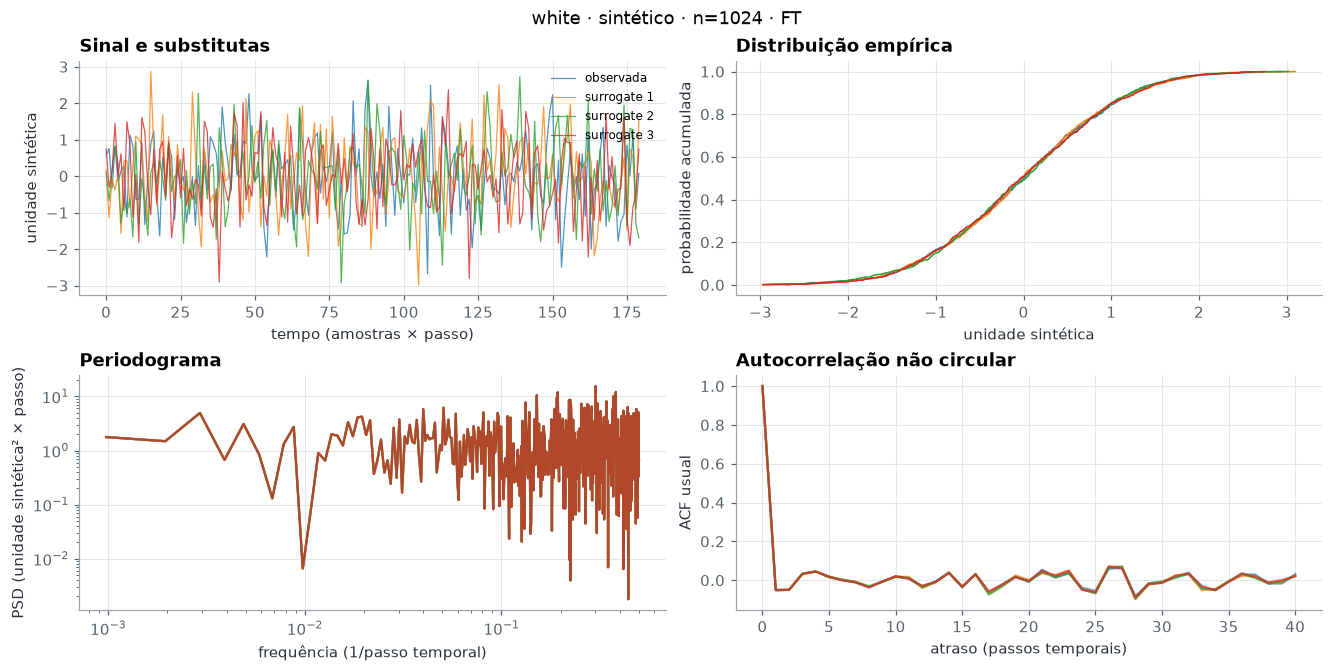

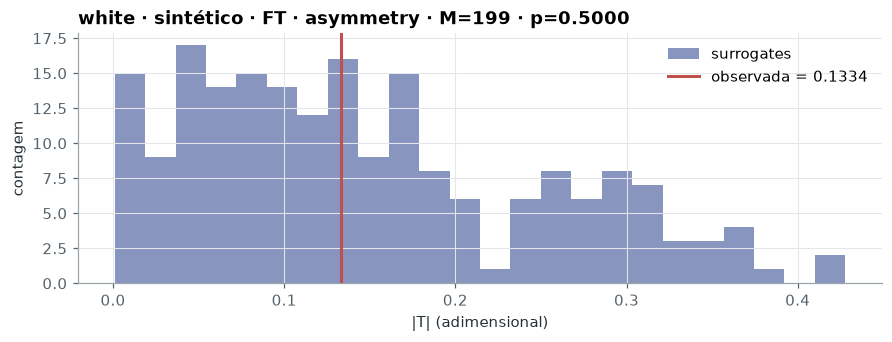

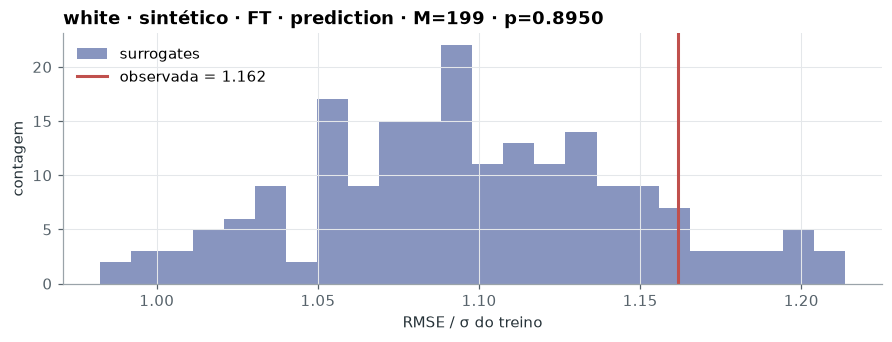

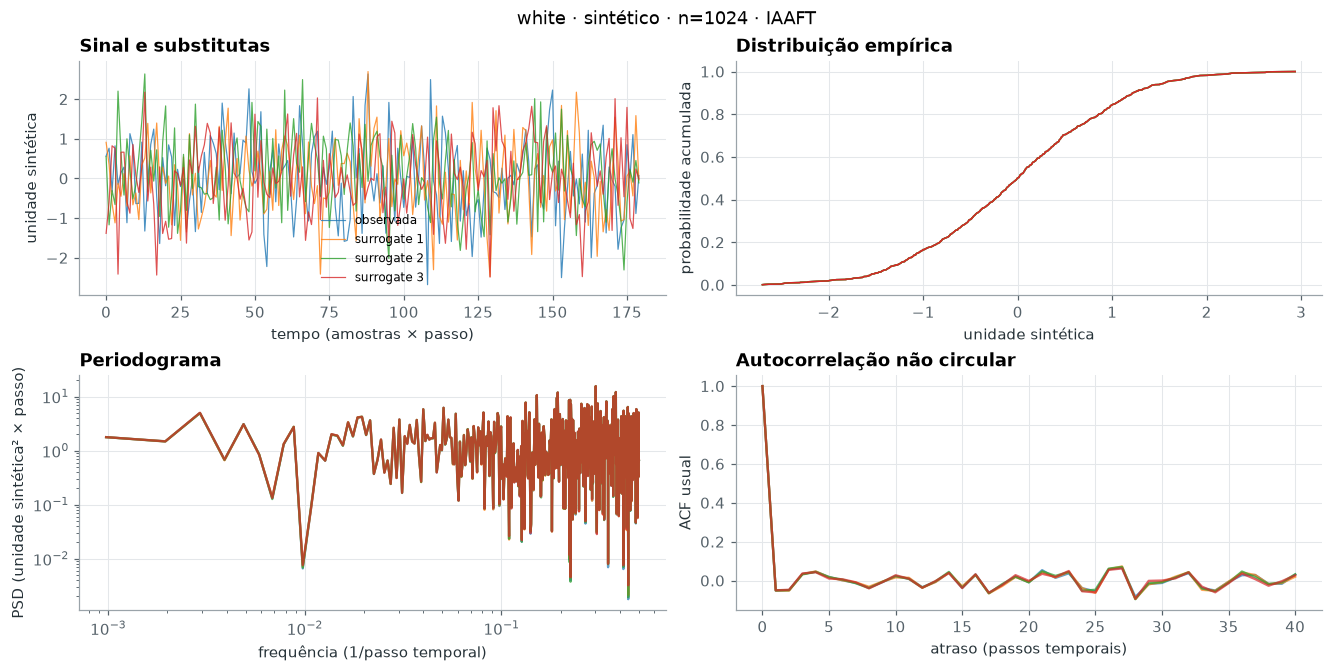

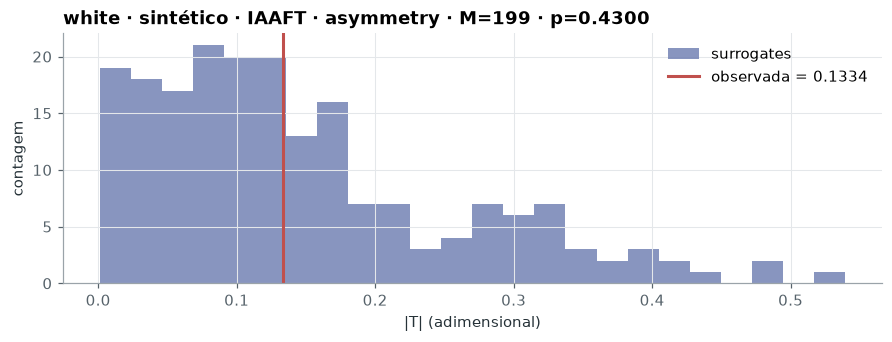

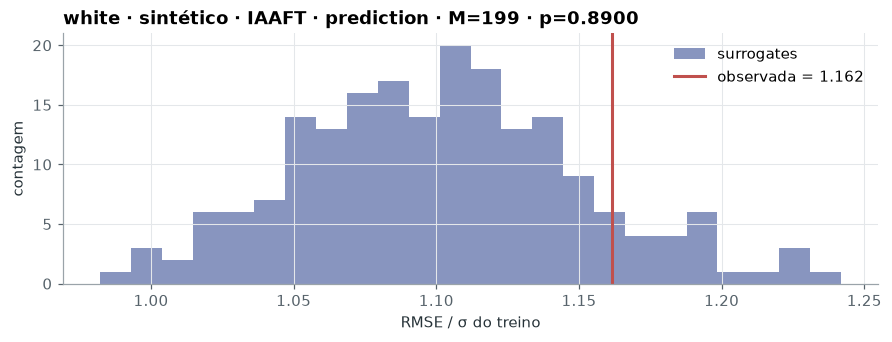

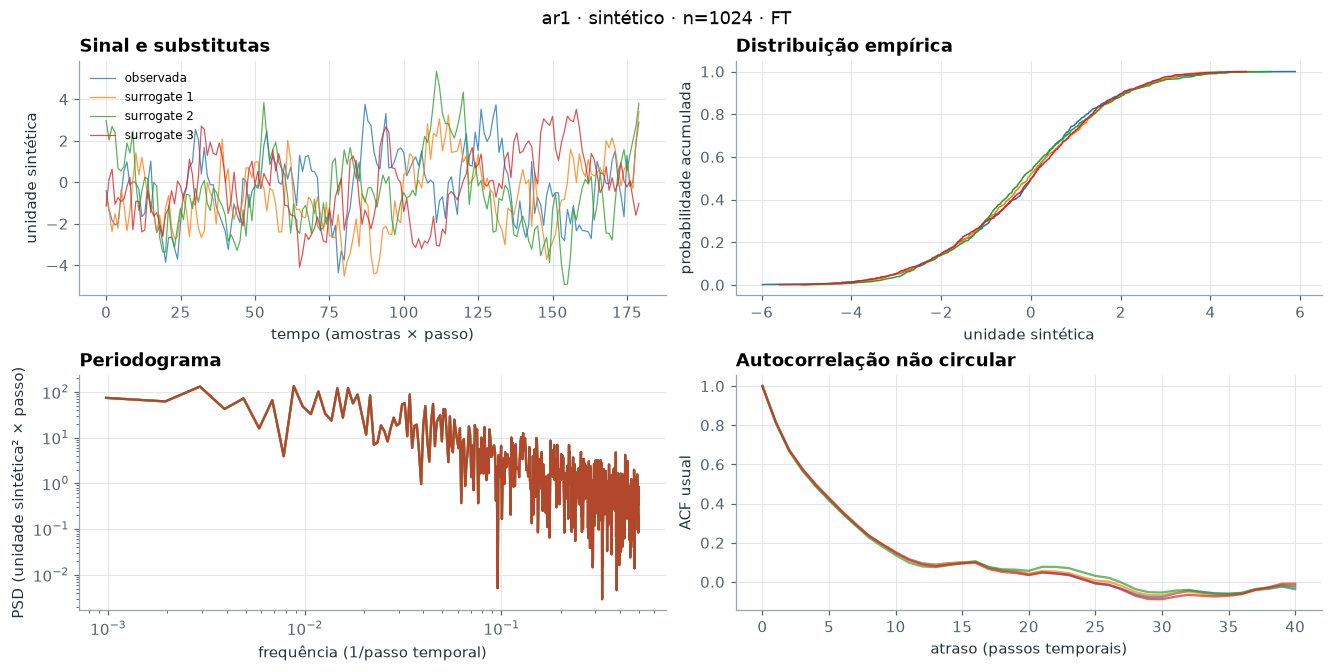

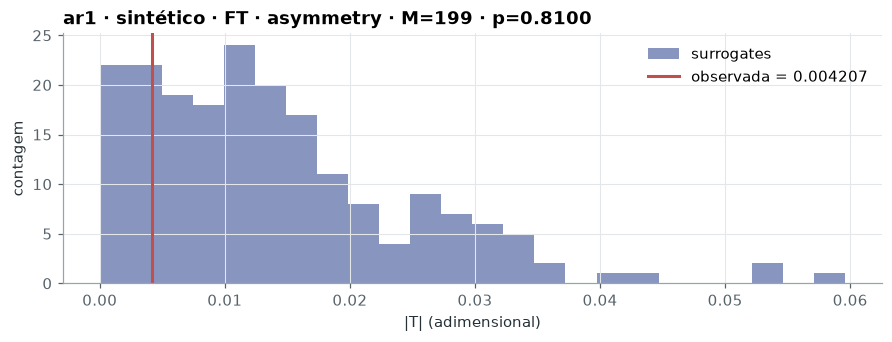

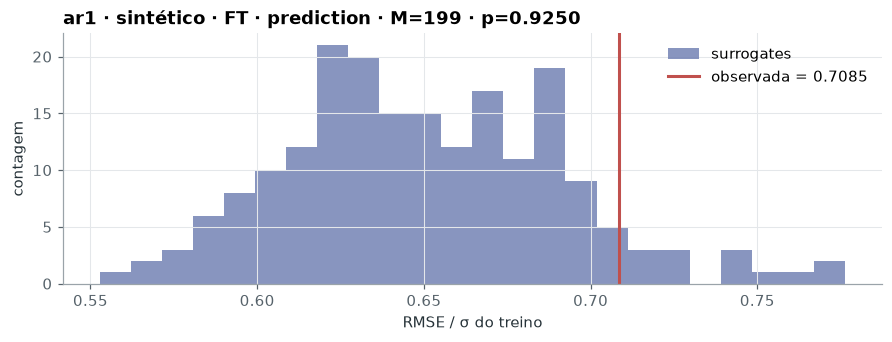

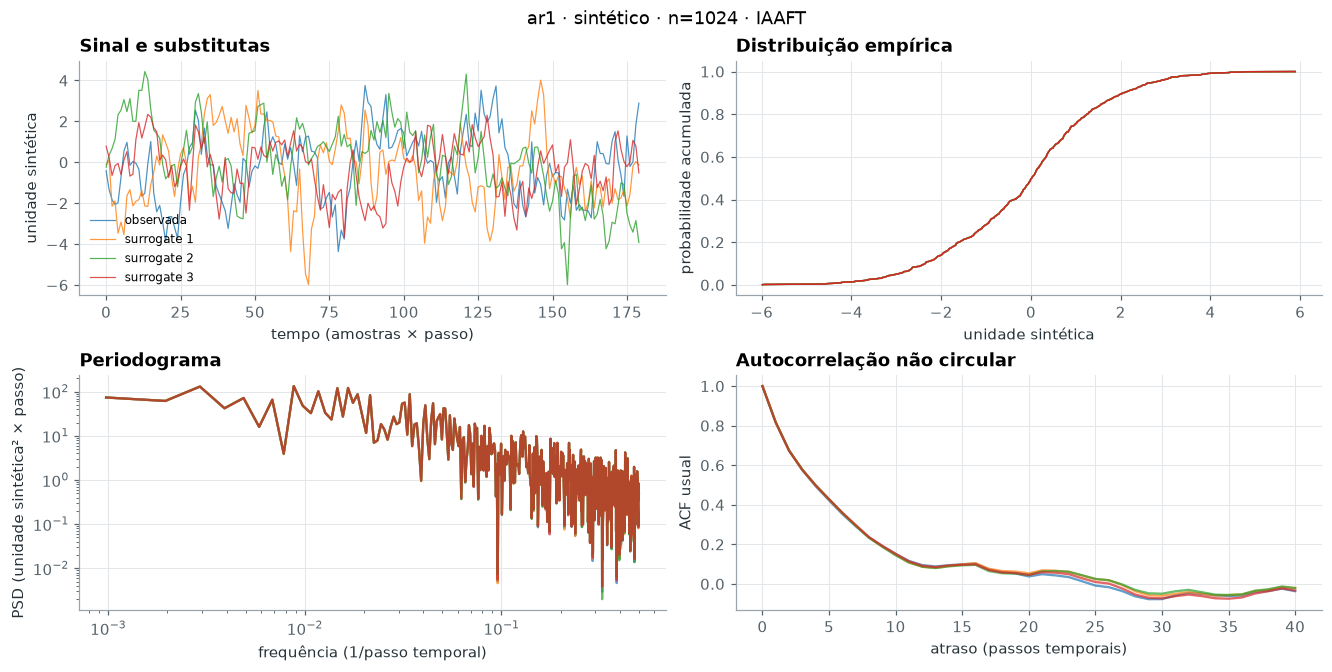

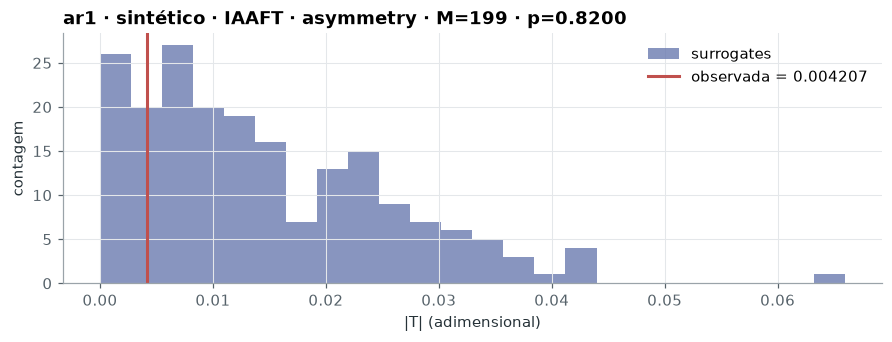

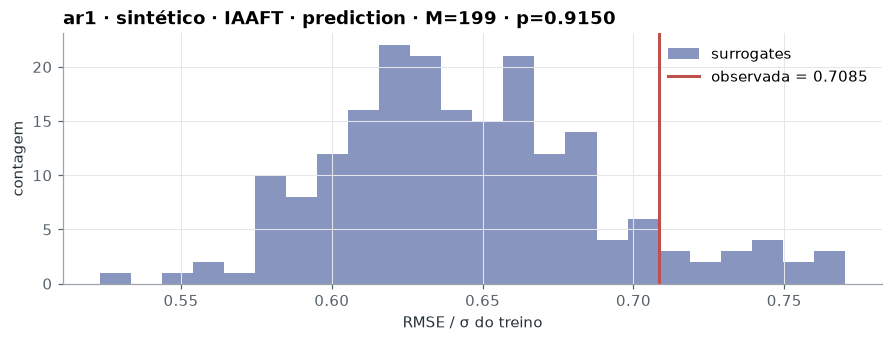

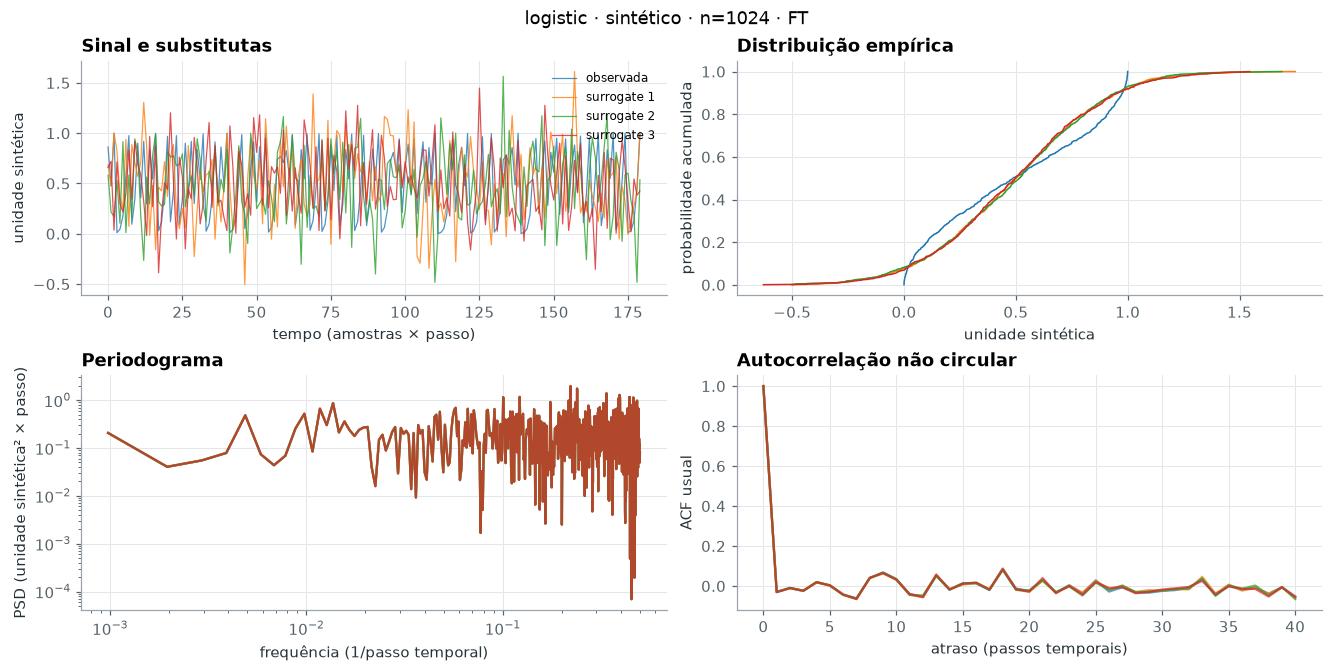

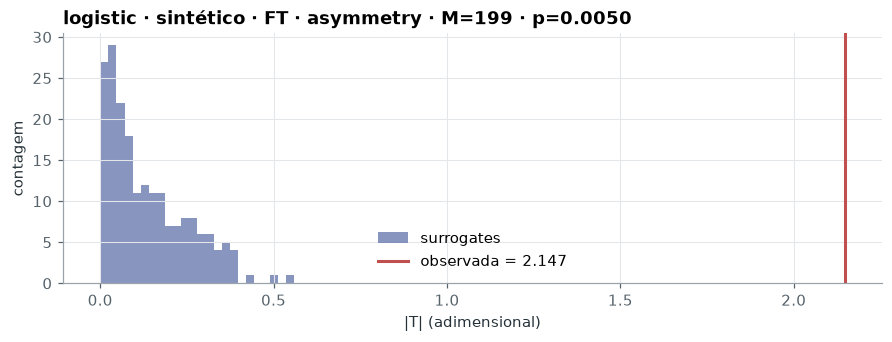

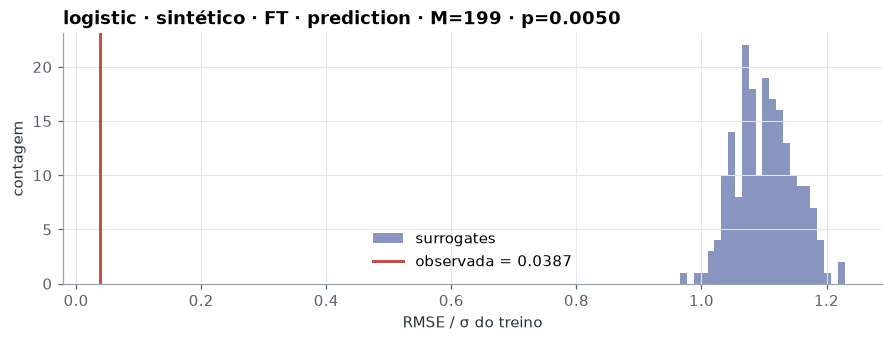

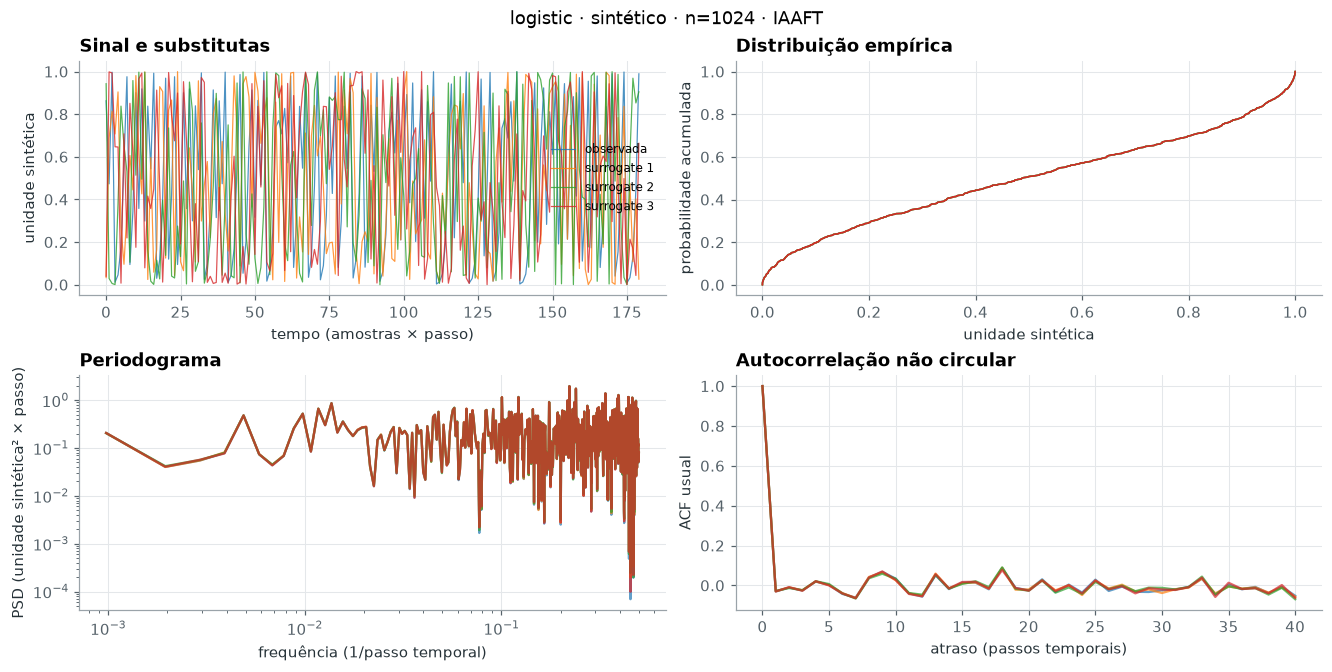

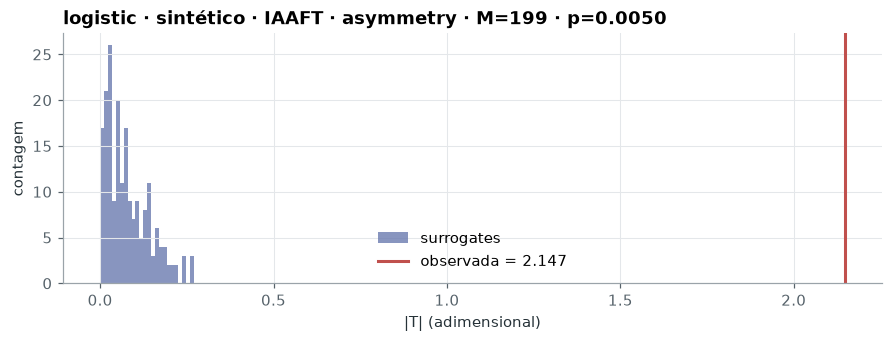

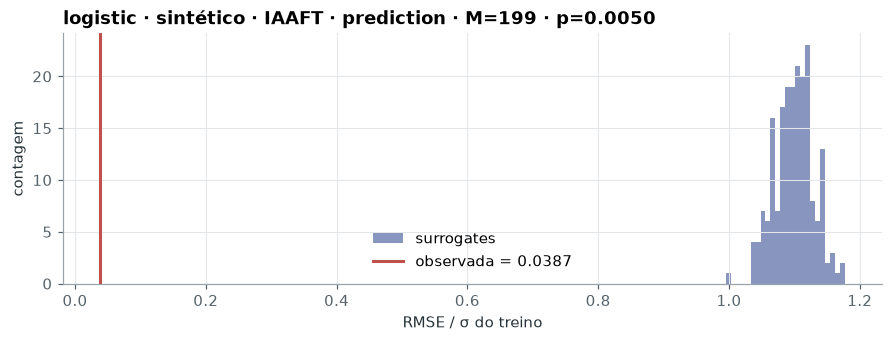

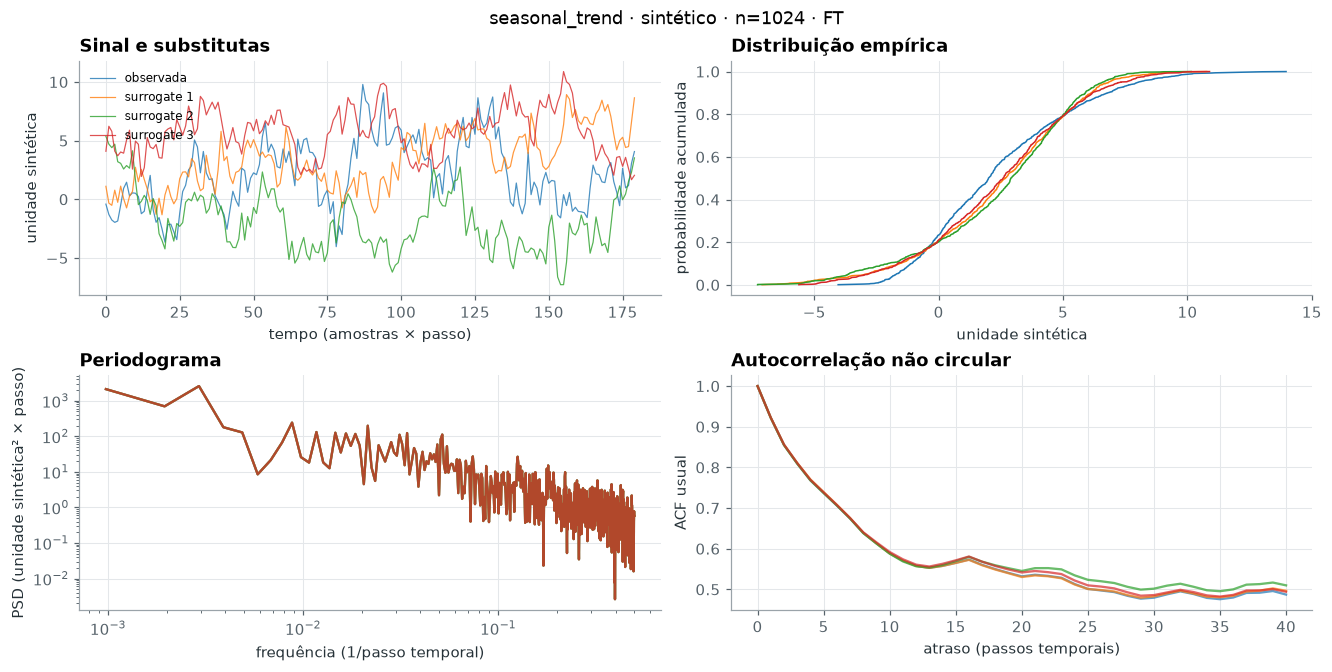

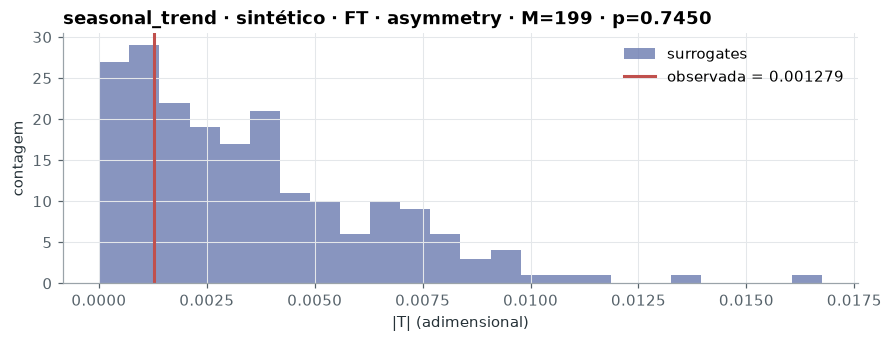

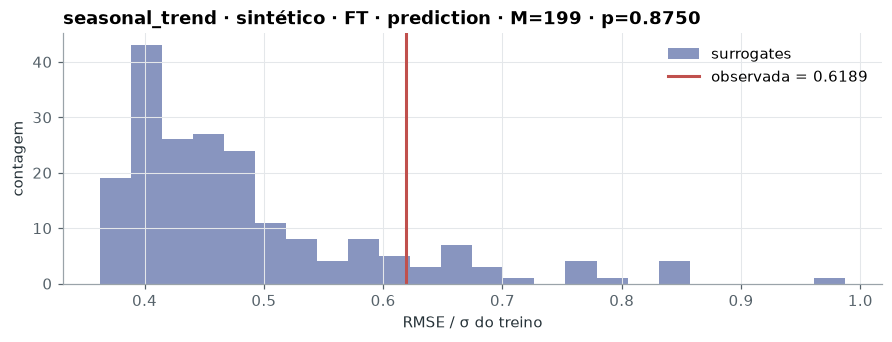

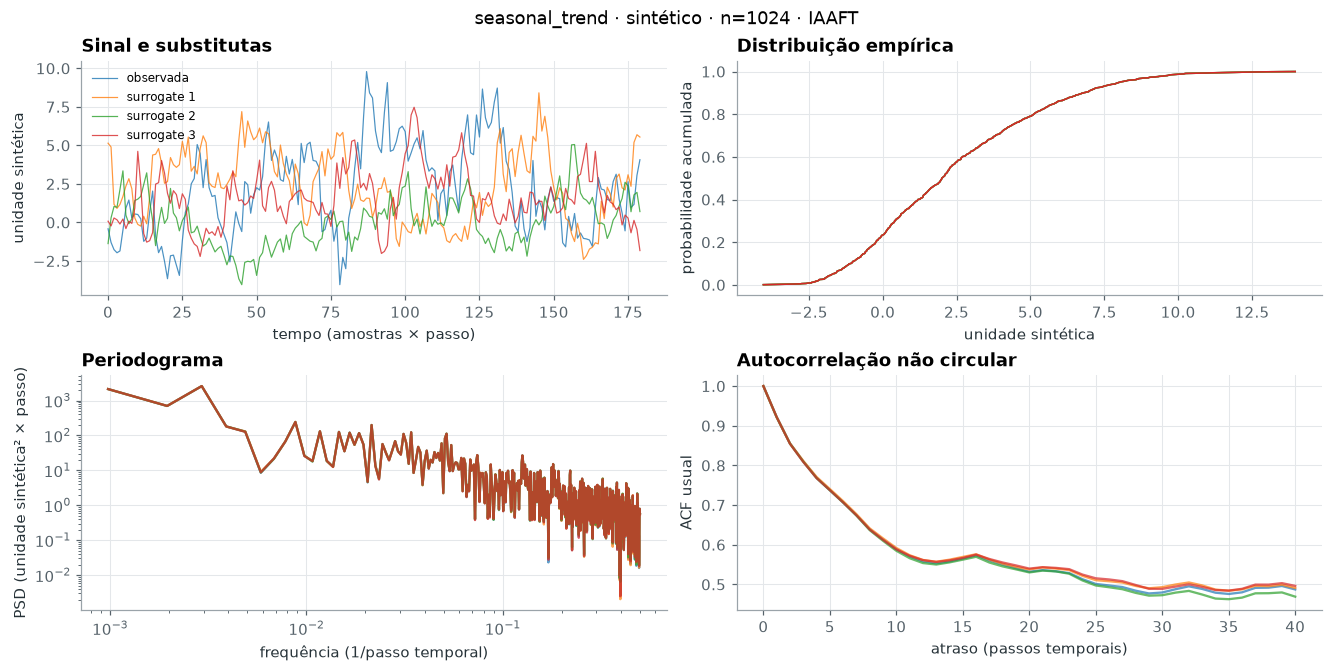

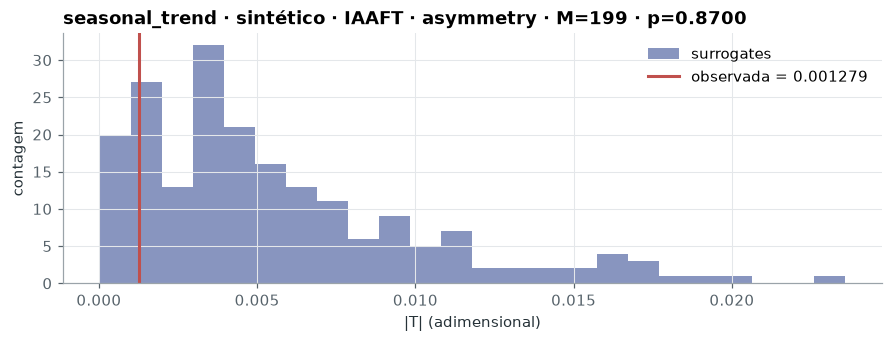

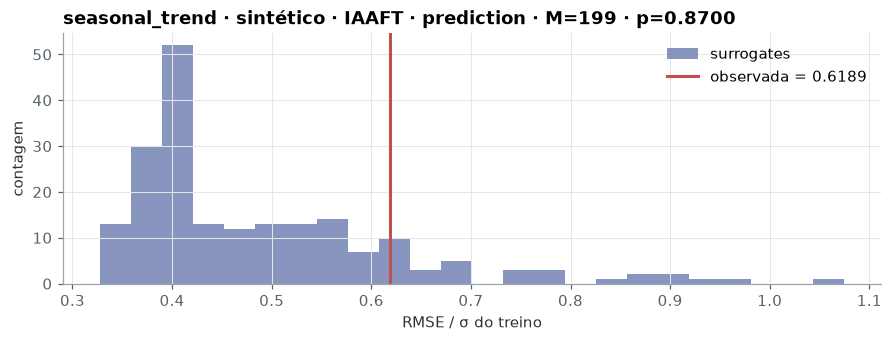

,control,method,statistic,observed,p_raw,p_adjusted,decision
0,white,FT,asymmetry,-0.133429,0.500,0.925,não rejeitamos a hipótese nula
1,white,FT,prediction,1.161663,0.895,0.925,não rejeitamos a hipótese nula
2,white,IAAFT,asymmetry,-0.133429,0.430,0.925,não rejeitamos a hipótese nula
3,white,IAAFT,prediction,1.161663,0.890,0.925,não rejeitamos a hipótese nula
4,ar1,FT,asymmetry,-0.004207,0.810,0.925,não rejeitamos a hipótese nula
5,ar1,FT,prediction,0.708512,0.925,0.925,não rejeitamos a hipótese nula
6,ar1,IAAFT,asymmetry,-0.004207,0.820,0.925,não rejeitamos a hipótese nula
7,ar1,IAAFT,prediction,0.708512,0.915,0.925,não rejeitamos a hipótese nula
8,logistic,FT,asymmetry,-2.146707,0.005,0.020,rejeitamos a hipótese nula
9,logistic,FT,prediction,0.038702,0.005,0.020,rejeitamos a hipótese nula


In [7]:
def control(kind, n, seed, noise=0.):
    rng = np.random.default_rng(seed)
    if kind == 'white':
        return rng.normal(size=n)
    if kind == 'ar1':
        return ar1(phi=.8, n=n+512, seed=seed)[512:]
    if kind == 'logistic':
        return logistic_map(x0=rng.uniform(.1, .9), n=n) + noise * rng.normal(size=n)
    t = np.arange(n)
    return control('ar1', n, seed) * (1 + .7*np.sin(2*np.pi*t/365)) + 3*np.sin(2*np.pi*t/365) + 5*t/n

synthetic_rows = []
for kind in ['white', 'ar1', 'logistic', 'seasonal_trend']:
    x = control(kind, 1024, CONFIG['seed'])
    synthetic_diag, synthetic_blocks = stationarity_diagnostics(x)
    synthetic_blocks.to_csv(OUT / f'blocks_synthetic_{kind}.csv', index=False)
    for method in CONFIG['methods']:
        for statistic in CONFIG['statistics']:
            result = run_test(x, method, statistic)
            identifier = f'synthetic_{kind}_{method}_{statistic}'
            synthetic_rows.append(result_row(result, source='synthetic', control=kind,
                method=method, statistic=statistic, family='exploratory',
                stationarity_flags=synthetic_diag['flags']))
            persist_result(result, identifier)
            if statistic == 'asymmetry':
                fig = plot_validation(x, result, f'{kind} · sintético · n=1024 · {method}')
                save(fig, FIGURES, identifier + '_validation')
                plt.show()
                plt.close()
            fig = plot_null(result, f'{kind} · sintético · {method} · {statistic}', statistic == 'asymmetry')
            save(fig, FIGURES, identifier + '_null')
            plt.show()
            plt.close()
synthetic = adjust_results(pd.DataFrame(synthetic_rows), CONFIG['alpha'])
synthetic.to_csv(OUT / 'synthetic_examples.csv', index=False)
display(synthetic[['control', 'method', 'statistic', 'observed', 'p_raw', 'p_adjusted', 'decision']])

,control,method,rejections,replicates,rate,ci_low,ci_high,nominal_in_interval
0,ar1,FT,2,40,0.050,0.006114,0.169197,True
1,ar1,IAAFT,2,40,0.050,0.006114,0.169197,True
2,logistic,FT,40,40,1.000,0.911903,1.000000,False
3,logistic,IAAFT,40,40,1.000,0.911903,1.000000,False
4,white,FT,3,40,0.075,0.015742,0.203865,True
5,white,IAAFT,2,40,0.050,0.006114,0.169197,True


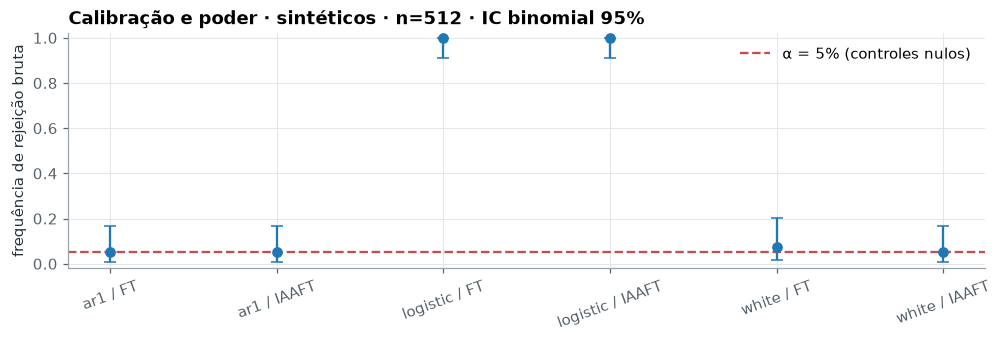

In [8]:
calibration_rows = []
calibration_streams = np.random.SeedSequence(CONFIG['seed']+100).spawn(CONFIG['calibration_repeats']*3)
cursor = 0
for kind in ['white', 'ar1', 'logistic']:
    for repetition in range(CONFIG['calibration_repeats']):
        data_stream, surrogate_stream = calibration_streams[cursor].spawn(2)
        cursor += 1
        data_seed = int(data_stream.generate_state(1)[0])
        surrogate_seed = int(surrogate_stream.generate_state(1)[0])
        x = control(kind, CONFIG['calibration_length'], data_seed)
        for method in CONFIG['methods']:
            result = run_test(x, method, seed=surrogate_seed)
            calibration_rows.append({'control': kind, 'method': method, 'replicate': repetition,
                'n': len(x), 'data_seed': data_seed, 'surrogate_seed': surrogate_seed,
                'p_raw': result.pvalue, 'rejected': result.pvalue <= CONFIG['alpha'],
                'spectral_error_max': result.diagnostics.spectral_error.max()})
calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(OUT / 'calibration_replicates.csv', index=False)
rates = []
for (kind, method), group in calibration.groupby(['control', 'method']):
    k, n = int(group.rejected.sum()), len(group)
    interval = binomtest(k, n).proportion_ci(confidence_level=.95, method='exact')
    rates.append({'control': kind, 'method': method, 'rejections': k, 'replicates': n,
                  'rate': k/n, 'ci_low': interval.low, 'ci_high': interval.high,
                  'nominal_in_interval': interval.low <= CONFIG['alpha'] <= interval.high})
rates = pd.DataFrame(rates)
rates.to_csv(OUT / 'calibration_rates.csv', index=False)
display(rates)
fig, ax = plt.subplots(figsize=(9, 3), layout='constrained')
ax.errorbar(np.arange(len(rates)), rates.rate,
            yerr=np.array([rates.rate-rates.ci_low, rates.ci_high-rates.rate]), fmt='o', capsize=4)
ax.axhline(CONFIG['alpha'], color=COLORS['t2m'], ls='--', label='α = 5% (controles nulos)')
ax.set(xticks=np.arange(len(rates)), xticklabels=rates.control+' / '+rates.method,
       ylabel='frequência de rejeição bruta', ylim=(-.02, 1.02),
       title=f'Calibração e poder · sintéticos · n={CONFIG["calibration_length"]} · IC binomial 95%')
ax.tick_params(axis='x', rotation=20)
ax.legend()
save(fig, FIGURES, 'calibration_rates')
plt.show()
plt.close()

## 8. Testes com séries reais do Xingu e do Baixo Tapajós

Cruzamos recorte, variável, versão e método sem escolher resultados pelo valor-p.
A família primária contém apenas temperatura em anomalias, atraso 1 e assimetria.
A série original e chuva entram como análises complementares. Os valores-p são
computados se a série for regular e finita, mas **toda análise regional é
exploratória quanto à interpretação** enquanto suporte espacial e premissas de
estacionariedade não forem auditados. A correção múltipla não corrige uma nula
mal especificada. Linhas sem dados continuam na família planejada com p=1 para
a correção, mantendo valor-p bruto ausente e decisão “não executado”.

In [9]:
real_rows = []
for region in CONFIG['regions']:
    for variable in CONFIG['variables']:
        for version in CONFIG['versions']:
            key = (region, variable, version)
            for method in CONFIG['methods']:
                for statistic in CONFIG['statistics']:
                    family = ('primary' if variable == 't2m' and version == 'anomaly'
                              and statistic == 'asymmetry' else 'exploratory')
                    labels = {'source': 'ERA5', 'region': region, 'variable': variable,
                              'version': version, 'method': method, 'statistic': statistic, 'family': family,
                              'period': ' / '.join(CONFIG['period']), 'resolution': CONFIG['resolution']}
                    if key not in climate_series:
                        real_rows.append({**labels, 'null_hypothesis': NULLS[method], 'p_raw': np.nan,
                            'M': 0, 'status': 'não executado: dados ausentes/inadequados'})
                        continue
                    x, diag, provenance = climate_series[key]
                    result = run_test(x, method, statistic)
                    identifier = f'real_{region}_{variable}_{version}_{method}_{statistic}'
                    row = result_row(result, **labels)
                    row.update(n=len(x), status='exploratório', stationarity_flags=diag['flags'], provenance=provenance)
                    real_rows.append(row)
                    persist_result(result, identifier)
                    fig = plot_null(result, f'ERA5 · {region} · {variable} · {version} · {method} · {CONFIG["period"]}', statistic == 'asymmetry')
                    save(fig, FIGURES, identifier + '_null')
                    plt.show()
                    plt.close()
                    if statistic == 'asymmetry':
                        fig = plot_validation(x, result,
                            f'ERA5 · {region} · {variable} · {version} · {method} · {CONFIG["period"]}',
                            unit=real_data[region][1][variable], step=7 if CONFIG['resolution']=='7D' else 1)
                        save(fig, FIGURES, identifier + '_validation')
                        plt.show()
                        plt.close()
real_results = pd.DataFrame(real_rows)

## 9. Comparação dos resultados e análise de sensibilidade

Atrasos 1, 7 e 30 amostras, comprimentos 256/1024 e ruído aditivo gaussiano de
desvio 0/0,3 (unidades do mapa logístico) foram definidos antes dos resultados.
Não mudamos o protocolo primário conforme a sensibilidade. Para ERA5 testamos
as duas janelas fixas 2001–2012 e 2013–2024. As anomalias mantêm a **mesma**
normal 1991–2020, não uma normal recalculada para cada janela. Cada teste de
sensibilidade aparece na família exploratória e recebe BH junto aos demais
testes climáticos exploratórios; simulações constituem outra família.

In [10]:
sensitivity_rows = []
for n in CONFIG['sensitivity_lengths']:
    for noise in CONFIG['sensitivity_noise']:
        x = control('logistic', n, CONFIG['seed']+200, noise)
        for method in CONFIG['methods']:
            for lag in CONFIG['sensitivity_lags']:
                result = run_test(x, method, lag=lag)
                persist_result(result, f'sensitivity_logistic_{n}_{noise}_{method}_{lag}')
                sensitivity_rows.append(result_row(result, source='synthetic', control='logistic',
                    n=n, noise=noise, method=method, lag=lag, family='exploratory'))
sensitivity = adjust_results(pd.DataFrame(sensitivity_rows), CONFIG['alpha'])
sensitivity.to_csv(OUT / 'synthetic_sensitivity.csv', index=False)
display(sensitivity[['n', 'noise', 'lag', 'method', 'p_raw', 'p_adjusted', 'decision']])

climate_sensitivity = []
for (region, variable, version), (x, _, provenance) in climate_series.items():
    for start, end in CONFIG['sensitivity_windows']:
        window = x.loc[start:end]
        if len(window) < CONFIG['minimum_climate_samples']:
            continue
        diag, blocks = stationarity_diagnostics(window, CONFIG['stationarity_blocks'], CONFIG['hac_lags'])
        for method in CONFIG['methods']:
            for lag in CONFIG['sensitivity_lags']:
                result = run_test(window, method, lag=lag)
                identifier = f'window_{region}_{variable}_{version}_{method}_{start}_{lag}'
                persist_result(result, identifier)
                climate_sensitivity.append(result_row(result, source='ERA5', region=region,
                    variable=variable, version=version, period=f'{start} / {end}', method=method,
                    resolution=CONFIG['resolution'], lag=lag, statistic='asymmetry', family='exploratory',
                    n=len(window), status='exploratório', stationarity_flags=diag['flags'], provenance=provenance))
real_combined = pd.concat([real_results, pd.DataFrame(climate_sensitivity)], ignore_index=True)
real_combined = adjust_results(real_combined, CONFIG['alpha'])
real_combined.to_csv(OUT / 'real_results.csv', index=False)
display(real_combined[['region', 'variable', 'version', 'method', 'statistic', 'period',
                       'family', 'p_raw', 'p_adjusted', 'decision', 'status']])

if climate_series:
    display(Markdown('Consulte `stationarity.csv`, `blocks_*.csv` e `rolling_*.csv` antes de interpretar rejeições.'))
else:
    display(Markdown('**Nenhum teste real foi executado.** A tabela documenta os protocolos planejados sem valores-p fictícios.'))

,n,noise,lag,method,p_raw,p_adjusted,decision
0,256,0.0,1,FT,0.005,0.017143,rejeitamos a hipótese nula
1,256,0.0,7,FT,0.965,0.970000,não rejeitamos a hipótese nula
2,256,0.0,30,FT,0.735,0.882000,não rejeitamos a hipótese nula
3,256,0.0,1,IAAFT,0.005,0.017143,rejeitamos a hipótese nula
4,256,0.0,7,IAAFT,0.970,0.970000,não rejeitamos a hipótese nula
5,256,0.0,30,IAAFT,0.470,0.865263,não rejeitamos a hipótese nula
6,256,0.3,1,FT,0.010,0.030000,rejeitamos a hipótese nula
7,256,0.3,7,FT,0.785,0.897143,não rejeitamos a hipótese nula
8,256,0.3,30,FT,0.685,0.865263,não rejeitamos a hipótese nula
9,256,0.3,1,IAAFT,0.005,0.017143,rejeitamos a hipótese nula


,region,variable,version,method,statistic,period,family,p_raw,p_adjusted,decision,status
0,xingu,t2m,original,FT,asymmetry,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados
1,xingu,t2m,original,FT,prediction,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados
2,xingu,t2m,original,IAAFT,asymmetry,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados
3,xingu,t2m,original,IAAFT,prediction,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados
4,xingu,t2m,anomaly,FT,asymmetry,2001-01-01 / 2024-12-31,primary,NaN,1.0,não executado,não executado: dados ausentes/inadequados
5,xingu,t2m,anomaly,FT,prediction,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados
6,xingu,t2m,anomaly,IAAFT,asymmetry,2001-01-01 / 2024-12-31,primary,NaN,1.0,não executado,não executado: dados ausentes/inadequados
7,xingu,t2m,anomaly,IAAFT,prediction,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados
8,xingu,precip,original,FT,asymmetry,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados
9,xingu,precip,original,FT,prediction,2001-01-01 / 2024-12-31,exploratory,NaN,1.0,não executado,não executado: dados ausentes/inadequados


**Nenhum teste real foi executado.** A tabela documenta os protocolos planejados sem valores-p fictícios.

## 10. Discussão das limitações

- FT não preserva a marginal não gaussiana de chuva; sua rejeição pode refletir
  essa inadequação. IAAFT preserva zeros e extremos, mas empates e erro espectral
  podem distorcer o tamanho do teste. Uma correção Holm/BH não resolve isso.
- Espectros condicionados a uma realização e conexão circular das pontas não
  equivalem a amostrar exatamente uma nula populacional. A diferença das pontas
  pode introduzir descontinuidades; não cortamos ou afunilamos a série só para
  conseguir significância. Janelas e tratamento das pontas exigem novo protocolo.
- Sazonalidade na variância, tendências, mudanças de ACF e suporte espacial variável
  podem causar rejeições sem dinâmica não linear. ADF/KPSS/CUSUM têm limitações
  de dependência serial e amostra finita. Não removemos tendências automaticamente.
- Assimetria usa terceiro momento e pode ser dominada por eventos raros. Atraso
  1 não detecta todas as dependências. O mapa logístico também tem perda de poder
  em certos atrasos e com ruído. Um controle significativo não valida todo cenário.
- Previsão usa holdout e exclusão temporal fixos, mas diferenças entre os períodos
  de treino e teste continuam relevantes. BH pressupõe independência ou certas
  formas de dependência positiva; a dependência entre protocolos pede cautela.
- O baseline inclui parte da janela científica; climatologia é uma estimativa
  descritiva da normal, não previsão fora da amostra. Sua incerteza não é propagada
  pelo teste condicionado. Suavização e convenção bissexta precisam de sensibilidade.
- ERA5 inclui assimilação, resolução espacial e arredondamento EDH (D-007), que
  podem afetar descritores de pequena escala. Médias regionais misturam regimes.
  Estes testes não estabelecem causalidade, tipping points ou caos determinístico.

## 11. Conclusões provisórias e próximos passos

A conclusão é construída a partir dos arquivos efetivamente lidos e da calibração,
não de uma expectativa de encontrar caos. Primeiro auditar suporte espacial,
referência e janelas, depois considerar estatísticas adicionais ou métodos de
dinâmica não linear. Não rejeições também são informativas dentro do poder
disponível. Os resultados abaixo indicam precisamente o que foi executado.

In [11]:
null_rates = rates[rates.control.isin(['white', 'ar1'])]
positive_rates = rates[rates.control == 'logistic']
lines = [f'Execução **{RUN_ID}**: M={CONFIG["n_surrogates"]}; modo rápido={QUICK}.',
         f'Testes ERA5 computados: **{int(real_combined.p_raw.notna().sum())}**.',
         'Rejeitar a nula não comprova caos; não rejeitar não comprova linearidade.']
for _, row in null_rates.iterrows():
    lines.append(f'Controle nulo {row.control}/{row.method}: {int(row.rejections)}/{int(row.replicates)} rejeições; '
                 f'IC95% [{row.ci_low:.3f}, {row.ci_high:.3f}].')
for _, row in positive_rates.iterrows():
    lines.append(f'Logístico/{row.method}: poder empírico {row.rate:.3f}; IC95% [{row.ci_low:.3f}, {row.ci_high:.3f}].')
if not real_data:
    lines.append('Não há conclusão climática: faltam os diários/resumos ERA5 locais do Xingu e Tapajós; caminhos em inventory.csv.')
if QUICK:
    lines.append('Este modo valida execução; não sustenta inferência científica.')
if (~null_rates.nominal_in_interval).any():
    lines.append('ALERTA: ao menos um intervalo de calibração não inclui 5%; ampliar simulações antes de inferência.')
(OUT / 'conclusions.md').write_text('\n\n'.join(lines), encoding='utf-8')
display(Markdown('\n\n'.join(lines)))
code_paths = ['src/amazon_chaos/nonlinear/surrogates.py', 'src/amazon_chaos/nonlinear/statistics.py',
              'src/amazon_chaos/nonlinear/surrogate_study.py', 'scripts/build_surrogate_notebook.py',
              'src/amazon_chaos/regional.py', 'src/amazon_chaos/preprocess/daily.py',
              'src/amazon_chaos/nonlinear/synthetic.py', 'src/amazon_chaos/nonlinear/embedding.py',
              'uv.lock', 'configs/xingu_1990_2024.yaml', 'configs/tapajos_1990_2024.yaml']
checksums = {p: hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in code_paths}
for path in inventory.loc[inventory.available & (inventory.kind == 'summary'), 'path']:
    checksums[path] = hashlib.sha256((ROOT/path).read_bytes()).hexdigest()
(OUT / 'checksums.json').write_text(json.dumps(checksums, indent=2), encoding='utf-8')
print('Tabelas, distribuições e configuração:', OUT.relative_to(ROOT))
print('Figuras:', FIGURES.relative_to(ROOT))
plt.close('all')

Execução **full_e57802a1f7**: M=199; modo rápido=False.

Testes ERA5 computados: **0**.

Rejeitar a nula não comprova caos; não rejeitar não comprova linearidade.

Controle nulo ar1/FT: 2/40 rejeições; IC95% [0.006, 0.169].

Controle nulo ar1/IAAFT: 2/40 rejeições; IC95% [0.006, 0.169].

Controle nulo white/FT: 3/40 rejeições; IC95% [0.016, 0.204].

Controle nulo white/IAAFT: 2/40 rejeições; IC95% [0.006, 0.169].

Logístico/FT: poder empírico 1.000; IC95% [0.912, 1.000].

Logístico/IAAFT: poder empírico 1.000; IC95% [0.912, 1.000].

Não há conclusão climática: faltam os diários/resumos ERA5 locais do Xingu e Tapajós; caminhos em inventory.csv.

Tabelas, distribuições e configuração: experiments\surrogates\full_e57802a1f7
Figuras: reports\figures\surrogates\full_e57802a1f7
